# The RAW and confirmed files at 532 nm

The set read here is the one the other notebook describes: every export in the seven quality-rated
RRUFF archives that says RAW and whose identification is confirmed, with `LR-Raman` left out. This
notebook takes that set and keeps only the files whose name carries 532 as the excitation wavelength,
so every table below is about the one excitation.

The files are counted by archive, then by mineral.


## 1. Setting up

The archives are looked for under `~/Desktop/raman_data` unless `RRUFF_DATA` points somewhere else.
The seven archives are named here, so are the header fields the set is filtered on, and so is the
excitation wavelength this notebook keeps.


In [1]:
from __future__ import annotations

import os
import re
import time
from pathlib import Path

import pandas as pd

# The seven quality-rated archives. LR-Raman is not one of them: it is a separate library of
# Raman spectra, so it is left out of the set.
ARCHIVES = [
    "excellent_oriented",
    "excellent_unoriented",
    "fair_oriented",
    "fair_unoriented",
    "poor_unoriented",
    "unrated_oriented",
    "unrated_unoriented",
]

# FILETYPE names the export kind, so a RAW file is picked out by that field rather than by the
# file name. STATUS carries RRUFF's sentence about the identification; a sentence recorded as
# "...is not yet confirmed", as the bare "Unconfirmed", or as a wording without the "yet" is
# matched by one of the three markers read as a substring.
UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")

# The fourth field of the file name carries the excitation wavelength. Only the files that write
# this one are kept, so no other excitation reaches the tables.
LASER = "532"

DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

# Used by the reader below, so they are defined next to the paths rather than inside it.
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
LEADING = "+-."

absent = [name for name in ARCHIVES if not (DATA_ROOT / name).is_dir()]
if absent:
    raise FileNotFoundError(f"these archive directories are missing under {DATA_ROOT}: {absent}")

print(f"reading {len(ARCHIVES)} archives from {DATA_ROOT}, keeping {LASER} nm")
for name in ARCHIVES:
    print(f"  {name:22s} {len(list((DATA_ROOT / name).glob('*.txt'))):7,d} files")


reading 7 archives from /home/raj/Desktop/raman_data, keeping 532 nm
  excellent_oriented       7,668 files
  excellent_unoriented    11,415 files
  fair_oriented               25 files
  fair_unoriented          2,951 files
  poor_unoriented          1,639 files
  unrated_oriented         3,778 files
  unrated_unoriented         639 files


## 2. Reading one export

A file is a `##KEY=value` block, then the data rows. The traps the reader has to survive are the
ones the other notebooks describe: a value wrapped onto the following line, a key written twice, and
comment lines inside the data block. The reader is repeated here in full so that this notebook runs
on its own.

Nothing here reads the data rows, so no spectrum is loaded and the pass over the archives is cheap.


In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the header fields as a dict, and a dict describing the data block with the
        keys points, x_min, x_max, wrapped_values, repeated_keys, comment_notes,
        separator, crlf and encoding.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout


## 3. The files the set keeps

Every file in the seven archives is read for its header. A file is kept when its `FILETYPE` says RAW
and its `STATUS` sentence does not carry any of the unconfirmed markers. The table counts the four
combinations of the two fields, so the size of the pool the set comes out of is on the page next to
the size of the set itself.


In [3]:
started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DATA_ROOT / archive).glob("*.txt")):
        header, _ = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        records.append({
            "archive": archive,
            "path": str(path),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            # The file name carries the excitation wavelength the export was written at,
            # in the fourth field of its "__"-separated stem.
            "wavelength": path.stem.split("__")[3],
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "status": header.get("STATUS", ""),
        })

pool = pd.DataFrame.from_records(records)
print(f"read {len(pool):,} headers in {time.time() - started:.1f}s")
print()

unconfirmed = pool.status.str.strip().str.lower().map(
    lambda sentence: any(marker in sentence for marker in UNCONFIRMED_MARKERS))
raw = pool.kind == "RAW"
kept = pool[raw & ~unconfirmed].copy()

counts = pd.DataFrame({
    "confirmed": [int((raw & ~unconfirmed).sum()), int((~raw & ~unconfirmed).sum())],
    "unconfirmed": [int((raw & unconfirmed).sum()), int((~raw & unconfirmed).sum())],
}, index=["RAW", "Processed"])
counts["files"] = counts.sum(axis=1)
counts.loc["all files"] = counts.sum()
counts = counts.astype(int)

print(f"the pool:     {len(pool):7,d} files")
print(f"the kept set: {len(kept):7,d} files ({len(kept) / len(pool) * 100:.1f}% of the pool)")
print()
print(counts.to_string())


read 28,115 headers in 14.0s

the pool:      28,115 files
the kept set:  13,154 files (46.8% of the pool)

           confirmed  unconfirmed  files
RAW            13154          954  14108
Processed      13054          953  14007
all files      26208         1907  28115


## 4. Narrowed to 532 nm

The kept set is cut down to the files whose name carries this excitation. The table counts the files
by the archive they were read out of.


In [4]:
at_532 = kept[kept.wavelength == LASER].copy()

by_archive = at_532.groupby("archive").size().rename("files").sort_values(ascending=False).to_frame()
by_archive.index.name = "archive"
by_archive.loc["all archives"] = int(by_archive["files"].sum())

print(f"{len(at_532):,} of the {len(kept):,} kept files are at {LASER} nm "
      f"({len(at_532) / len(kept) * 100:.1f}%), across {at_532.mineral.nunique():,} minerals")
print()
print(by_archive.to_string())


3,509 of the 13,154 kept files are at 532 nm (26.7%), across 2,044 minerals

                      files
archive                    
excellent_unoriented   2612
fair_unoriented         533
poor_unoriented         209
unrated_unoriented      151
unrated_oriented          4
all archives           3509


## 5. The files per mineral

One row per mineral holding a file at this excitation, largest first, then a row of the summary
numbers over those minerals.


In [5]:
per_mineral = (at_532.groupby("mineral").size()
              .rename("files")
              .sort_values(ascending=False, kind="stable")
              .to_frame())
per_mineral.index.name = "mineral"

summary = pd.DataFrame({
    "minerals": [int(per_mineral.shape[0])],
    "files": [int(per_mineral["files"].sum())],
    "mean": [float(per_mineral["files"].mean())],
    "min": [int(per_mineral["files"].min())],
    "max": [int(per_mineral["files"].max())],
    "median": [float(per_mineral["files"].median())],
})

print(summary.round({"mean": 2, "median": 2}).to_string(index=False))
print()
print(per_mineral.to_string())

 minerals  files  mean  min  max  median
     2044   3509  1.72    1   19     1.0

                                       files
mineral                                     
Grossular                                 19
Beryl                                     16
Corundum                                  15
Diamond                                   14
Diopside                                  14
Fluorapatite                              14
Andradite                                 13
Enstatite                                 12
Epidote                                   12
Spinel                                    12
Almandine                                 11
Elbaite                                   11
Forsterite                                11
Calcite                                   10
Jamesonite                                10
Marialite                                 10
Pyrope                                    10
Quartz                                    10
Tremolite        

## 6. The difference in range coverage between the files of a mineral

The range of a file is the smallest and the largest wavenumber in its data block. Every file at
this excitation is read in full for that here, so this is the first section that looks at a
wavenumber rather than only at a header.

For each mineral, every pair of its files is taken, and the difference in range coverage of that
pair is the wavenumber span covered by exactly one of the two files: the part of the axis one file
reports and the other does not, in cm-1. Two files spanning the same range differ by zero, and two
files whose ranges do not touch at all differ by the sum of their two widths.

The table gives one row per mineral holding two or more files, with the number of files, the number
of pairs they make, and the mean, median, largest and smallest difference over those pairs, to two
decimals. Rows run from the largest mean difference down. A mineral holding a single file makes no
pair, so it is left out, and the count of those minerals is printed above the table.


In [6]:
from itertools import combinations

import numpy as np


def read_range(path):
    """The smallest and largest wavenumber one export's data block holds, in cm-1.

    The whole block is read rather than its end rows alone, because the order an export writes its
    axis in is not guaranteed. Header lines and comment lines inside the block start with a hash,
    so they are skipped, and a line that is not two numbers is passed over.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: (low, high), or None when the data block holds no usable row.
    """
    values = []
    text = path.read_text(encoding="utf-8", errors="replace").replace("\r\n", "\n")
    for line in text.split("\n"):
        stripped = line.strip()
        if not stripped or stripped.startswith("#"):
            continue
        fields = stripped.replace(",", " ").split()
        if len(fields) == 2:
            try:
                values.append(float(fields[0]))
            except ValueError:
                pass
    return (min(values), max(values)) if values else None


def coverage_difference(low_a, high_a, low_b, high_b):
    """The wavenumber span covered by exactly one of two ranges, in cm-1.

    Each range's width has the overlap of the two taken off it, so the result is the part of the
    axis the two files do not agree on: the ends one file reaches past the other. Two files
    spanning the same range differ by zero, and two ranges that do not touch differ by the sum of
    their two widths.
    """
    overlap = max(0.0, min(high_a, high_b) - max(low_a, low_b))
    return (high_a - low_a) + (high_b - low_b) - 2.0 * overlap


started = time.time()
file_rows = []
for row in at_532.itertuples():
    span = read_range(Path(row.path))
    if span is None:
        continue
    file_rows.append({
        "mineral": row.mineral,
        "rruff_id": row.rruff_id,
        "archive": row.archive,
        "path": row.path,
        "low": span[0],
        "high": span[1],
    })
spans = pd.DataFrame.from_records(file_rows)

mineral_rows, every = [], []
for mineral, group in spans.groupby("mineral", sort=True):
    ends = list(zip(group.low, group.high))
    differences = [coverage_difference(*left, *right) for left, right in combinations(ends, 2)]
    every.extend(differences)
    mineral_rows.append({
        "mineral": mineral,
        "files": len(group),
        "pairs": len(differences),
        "mean": float(np.mean(differences)) if differences else np.nan,
        "median": float(np.median(differences)) if differences else np.nan,
        "max": float(np.max(differences)) if differences else np.nan,
        "min": float(np.min(differences)) if differences else np.nan,
    })
coverage = pd.DataFrame.from_records(mineral_rows)
paired = coverage[coverage.pairs > 0].sort_values("mean", ascending=False)

print(f"read the range of {len(spans):,} spectra in {time.time() - started:.1f}s")
print(f"minerals holding a file at this excitation: {len(coverage):,}, {len(paired):,} of them "
      f"holding two or more files")
print(f"minerals holding a single file, and so no pair: {int((coverage.pairs == 0).sum()):,}")
print()
print(f"over all {len(every):,} pairs of files of one mineral, in cm-1:")
print(pd.DataFrame({
    "pairs": [len(every)],
    "mean": [float(np.mean(every))],
    "median": [float(np.median(every))],
    "max": [float(np.max(every))],
    "min": [float(np.min(every))],
}).round(2).to_string(index=False))
print()
print("per mineral, ordered by mean difference, largest first, in cm-1:")
print(paired.round({"mean": 2, "median": 2, "max": 2, "min": 2}).to_string(index=False))


read the range of 3,509 spectra in 4.2s
minerals holding a file at this excitation: 2,044, 757 of them holding two or more files
minerals holding a single file, and so no pair: 1,287

over all 3,635 pairs of files of one mineral, in cm-1:
 pairs  mean  median     max  min
  3635 77.33   35.68 5219.88  0.0

per mineral, ordered by mean difference, largest first, in cm-1:
                    mineral  files  pairs    mean  median     max     min
                Aenigmatite      2      1 5219.88 5219.88 5219.88 5219.88
              Castellaroite      2      1 2800.00 2800.00 2800.00 2800.00
                    Diamond     14     91 1444.47 2571.61 2774.58    0.00
                  Benitoite      3      3 1135.59 1696.09 1702.50    8.20
                  Trevorite      2      1  707.75  707.75  707.75  707.75
                  Tinticite      2      1  596.28  596.28  596.28  596.28
             Hydromagnesite      2      1  547.54  547.54  547.54  547.54
                    Cechite      2 

## 7. The sources of the files

The three archives holding the most files at this excitation are drawn as three sets. Each name is
written outside its circle with the number of files the archive holds, and the size of each of the
seven regions is written inside it.

A file is exported into one archive, so no file lies in two of these sets and the four regions
where the circles cross are empty. The diagram says which archive each file comes from, and nothing
past that. The files from the unrated archives lie outside the three sets and are counted in the
text below the figure.


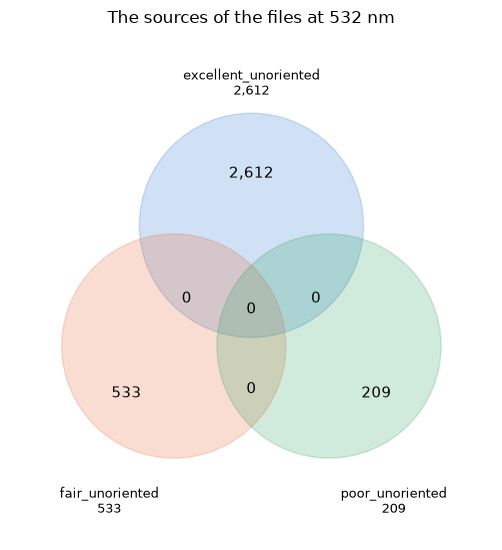

excellent_unoriented only                       2,612 files
fair_unoriented only                              533 files
poor_unoriented only                              209 files
excellent_unoriented & fair_unoriented              0 files
excellent_unoriented & poor_unoriented              0 files
fair_unoriented & poor_unoriented                   0 files
all three                                           0 files

the three archives hold 3,354 of the 3,509 files, and the unrated archives hold the other 155 (151 unoriented, 4 oriented)
a file is exported into one archive, so the regions where the circles cross are empty


In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

# The three archives holding the most files at this excitation. The unrated archives are outside
# the diagram, and the caption below the figure counts the files they hold.
SOURCES = ["excellent_unoriented", "fair_unoriented", "poor_unoriented"]


def draw_three_set_venn(names, sets, title):
    """Draw three overlapping circles and write the size of each region in it.

    The first set is drawn at the top, the second at the lower left and the third at the lower
    right. Each name is written outside its own circle, with the total size of the set under it,
    and the size of each of the seven regions is written where the region lies: a number inside
    one circle is the part of that set no other set holds, a number where two circles cross is the
    part those two share, and the number in the middle is the part all three share.

    Args:
        names (list): the three set names, ordered top, lower left, lower right.
        sets (list): the three sets, in the same order as the names.
        title (str): the heading written over the figure.

    Returns:
        tuple: the figure, and the seven region sizes keyed by the sets a region belongs to, as
        {"<name> only": n, "<name> & <name>": n, "all three": n}.
    """
    top, low_left, low_right = sets
    sizes = [
        len(top - low_left - low_right),
        len(low_left - top - low_right),
        len(low_right - top - low_left),
        len((top & low_left) - low_right),
        len((top & low_right) - low_left),
        len((low_left & low_right) - top),
        len(top & low_left & low_right),
    ]
    labels = [
        f"{names[0]} only",
        f"{names[1]} only",
        f"{names[2]} only",
        f"{names[0]} & {names[1]}",
        f"{names[0]} & {names[2]}",
        f"{names[1]} & {names[2]}",
        "all three",
    ]
    positions = [(0.00, 0.60), (-0.58, -0.42), (0.58, -0.42),
                 (-0.30, 0.02), (0.30, 0.02), (0.00, -0.40), (0.00, -0.03)]

    figure, panel = plt.subplots(figsize=(7.0, 5.6))
    for centre, colour, name, total, label_at in (
            ((0.00, 0.36), "#2a78d6", names[0], len(top), (0.00, 1.02)),
            ((-0.36, -0.20), "#eb6834", names[1], len(low_left), (-0.66, -0.92)),
            ((0.36, -0.20), "#2ca25f", names[2], len(low_right), (0.66, -0.92))):
        panel.add_patch(plt.Circle(centre, 0.52, color=colour, alpha=0.22))
        panel.text(*label_at, f"{name}\n{total:,}", ha="center", va="center", fontsize=9)

    for position, size in zip(positions, sizes):
        panel.text(*position, f"{size:,}", ha="center", va="center", fontsize=11)

    panel.set_title(title)
    panel.set_xlim(-1.12, 1.12)
    panel.set_ylim(-1.10, 1.26)
    panel.set_aspect("equal")
    panel.axis("off")
    plt.tight_layout()
    return figure, dict(zip(labels, sizes))


file_sets = [set(at_532["path"][at_532["archive"] == source]) for source in SOURCES]

_, file_regions = draw_three_set_venn(SOURCES, file_sets, "The sources of the files at 532 nm")
plt.show()

for label, size in file_regions.items():
    print(f"{label:46s} {size:6,d} files")

unrated = at_532[~at_532["archive"].isin(SOURCES)]
print()
print(f"the three archives hold {len(set().union(*file_sets)):,} of the {len(at_532):,} files, and "
      f"the unrated archives hold the other {len(unrated):,} "
      f"({int((unrated['archive'] == 'unrated_unoriented').sum()):,} unoriented, "
      f"{int((unrated['archive'] == 'unrated_oriented').sum()):,} oriented)")
print("a file is exported into one archive, so the regions where the circles cross are empty")


## 8. The sources of the minerals

The same three archives, this time as sets of the minerals they hold rather than of the files. A
mineral can be written into more than one archive, so the regions where the circles cross hold the
minerals two archives share, and the middle region holds the minerals all three carry. Read against
the figure above, this is where the three archives stop being disjoint.


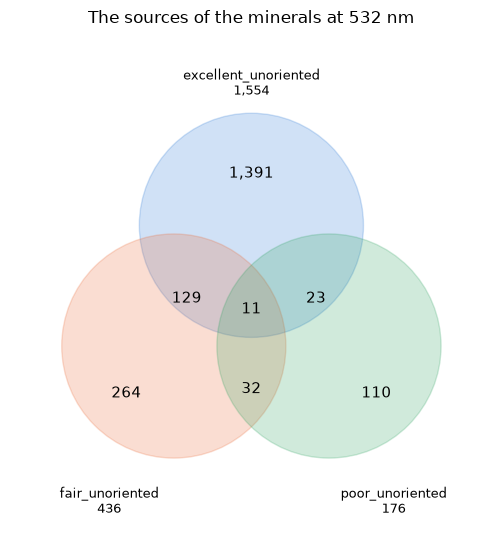

excellent_unoriented only                       1,391 minerals
fair_unoriented only                              264 minerals
poor_unoriented only                              110 minerals
excellent_unoriented & fair_unoriented            129 minerals
excellent_unoriented & poor_unoriented             23 minerals
fair_unoriented & poor_unoriented                  32 minerals
all three                                          11 minerals

1,960 minerals are written into these three archives, and a mineral the circles share is one written into two of them or into all three


In [8]:
mineral_sets = [set(at_532["mineral"][at_532["archive"] == source]) for source in SOURCES]

_, mineral_regions = draw_three_set_venn(SOURCES, mineral_sets,
                                         "The sources of the minerals at 532 nm")
plt.show()

for label, size in mineral_regions.items():
    print(f"{label:46s} {size:6,d} minerals")

print()
print(f"{len(set().union(*mineral_sets)):,} minerals are written into these three archives, and a "
      f"mineral the circles share is one written into two of them or into all three")


## 9. What this covers

| Section | Reports |
| --- | --- |
| 3 | the files the set keeps, and the RAW and confirmed filter they pass |
| 4 | how many of them are at 532 nm, and the archive each one was read out of |
| 5 | those files counted per mineral, with the summary numbers over the minerals |
| 6 | the range each file spans, and the difference in coverage between the files of a mineral |
| 7 | the archive each file comes from, over the three archives holding the most of them |
| 8 | those three archives again as sets of minerals, where they do overlap |


## 10. Reproducing

```
cd /home/raj/projects/SH_Project
MPLBACKEND=Agg .venv/bin/jupyter execute --inplace --kernel_name sh_project notebooks/raw_laser_532.ipynb
```

The archives are read from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is set.
